# 🔬 BACH Dataset Processing Pipeline

This notebook processes the ICIAR2018 BACH Challenge dataset for multi-dataset validation of JPEG2000 compression effects on breast cancer histopathology classification.

## Dataset Info
- **Source**: ICIAR2018 BACH Challenge
- **Images**: 400 microscopy images
- **Resolution**: 2048×1536 (resized to 224×224)
- **Classes**: 4 original → 2 binary (matching BreakHis)

---

## 📦 Cell 1: Install Dependencies

In [1]:
# Install required packages
!apt-get update -qq && apt-get install -qq -y libopenjp2-tools > /dev/null 2>&1
!pip install glymur pillow-heif --quiet

print("✅ Dependencies installed!")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 31.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.6/5.6 MB 116.8 MB/s eta 0:00:00
✅ Dependencies installed!


## 📚 Cell 2: Import Libraries

In [2]:
import os
import shutil
import zipfile
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from tqdm import tqdm
import subprocess
import warnings
warnings.filterwarnings('ignore')

# Try to import glymur for JPEG2000
try:
    import glymur
    GLYMUR_AVAILABLE = True
    print("✅ Glymur (JPEG2000) available")
except ImportError:
    GLYMUR_AVAILABLE = False
    print("⚠️ Glymur not available, will use OpenJPEG CLI")

print("✅ Libraries imported!")

✅ Glymur (JPEG2000) available
✅ Libraries imported!


## 🔧 Cell 3: Mount Drive & Configuration

In [3]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# ============================================================================
# 🔧 CONFIGURATION - UPDATE THE ZIP PATH!
# ============================================================================

class Config:
    """Configuration for BACH dataset processing"""

    # ⚠️ UPDATE THIS PATH to where you uploaded the zip file!
    BACH_ZIP_PATH = '/content/drive/MyDrive/ICIAR2018_BACH_Challenge.zip'

    # Output directories
    BASE_DIR = '/content/drive/MyDrive/BACH_PLOS_ONE'
    EXTRACTED_DIR = '/content/BACH_extracted'
    SPLIT_DIR = f'{BASE_DIR}/BACH_Split'

    # Processing parameters
    IMG_SIZE = (224, 224)  # Match BreakHis
    RANDOM_SEED = 42
    TEST_SIZE = 0.20
    VAL_SIZE = 0.15

    # JPEG2000 compression ratios (same as BreakHis)
    CR_LEVELS = [1, 15, 25, 50, 100, 500, 1000]

    # Class mapping: 4-class → 2-class (binary)
    CLASS_MAPPING = {
        'Normal': 'benign',
        'Benign': 'benign',
        'InSitu': 'malignant',
        'Invasive': 'malignant'
    }

    ORIGINAL_CLASSES = ['Normal', 'Benign', 'InSitu', 'Invasive']

CONFIG = Config()

# Create directories
os.makedirs(CONFIG.BASE_DIR, exist_ok=True)
os.makedirs(CONFIG.EXTRACTED_DIR, exist_ok=True)

print("="*60)
print("📁 Configuration:")
print(f"   ZIP path: {CONFIG.BACH_ZIP_PATH}")
print(f"   Output: {CONFIG.SPLIT_DIR}")
print("="*60)

# Verify zip exists
if os.path.exists(CONFIG.BACH_ZIP_PATH):
    size_gb = os.path.getsize(CONFIG.BACH_ZIP_PATH) / (1024**3)
    print(f"\n✅ ZIP file found! Size: {size_gb:.2f} GB")
else:
    print(f"\n❌ ZIP file NOT found at: {CONFIG.BACH_ZIP_PATH}")
    print("   Please update CONFIG.BACH_ZIP_PATH with the correct path")

Mounted at /content/drive
📁 Configuration:
   ZIP path: /content/drive/MyDrive/ICIAR2018_BACH_Challenge.zip
   Output: /content/drive/MyDrive/BACH_PLOS_ONE/BACH_Split

✅ ZIP file found! Size: 9.70 GB


## 📦 Cell 4: Extract Dataset

In [4]:
print("="*60)
print("📦 EXTRACTING BACH DATASET")
print("="*60)

if not os.path.exists(CONFIG.BACH_ZIP_PATH):
    raise FileNotFoundError(f"ZIP not found: {CONFIG.BACH_ZIP_PATH}")

# Check if already extracted
if os.path.exists(CONFIG.EXTRACTED_DIR) and len(os.listdir(CONFIG.EXTRACTED_DIR)) > 0:
    print("⚠️ Already extracted. Skipping...")
    print(f"   Contents: {os.listdir(CONFIG.EXTRACTED_DIR)}")
else:
    print(f"\n⏳ Extracting to: {CONFIG.EXTRACTED_DIR}")
    print("   This may take 5-10 minutes for 10 GB...")

    with zipfile.ZipFile(CONFIG.BACH_ZIP_PATH, 'r') as zip_ref:
        zip_ref.extractall(CONFIG.EXTRACTED_DIR)

    print("\n✅ Extraction complete!")

# List contents
print("\n📂 Extracted contents:")
for item in os.listdir(CONFIG.EXTRACTED_DIR):
    print(f"   {item}")

📦 EXTRACTING BACH DATASET

⏳ Extracting to: /content/BACH_extracted
   This may take 5-10 minutes for 10 GB...

✅ Extraction complete!

📂 Extracted contents:
   ICIAR2018_BACH_Challenge


## 🔍 Cell 5: Find and Explore Photos Directory

In [5]:
print("="*60)
print("🔍 FINDING MICROSCOPY IMAGES")
print("="*60)

def find_photos_directory(base_path):
    """Find the Photos directory containing microscopy images"""
    # Common paths in BACH dataset
    possible_paths = [
        f"{base_path}/ICIAR2018_BACH_Challenge/Photos",
        f"{base_path}/Photos",
        f"{base_path}/ICIAR2018_BACH_Challenge_TestDataset/Photos",
    ]

    for path in possible_paths:
        if os.path.exists(path):
            return path

    # Search for directories with class names
    for root, dirs, files in os.walk(base_path):
        if set(['Normal', 'Benign', 'InSitu', 'Invasive']).issubset(set(dirs)):
            return root
        if 'Photos' in dirs:
            return os.path.join(root, 'Photos')

    return None

PHOTOS_DIR = find_photos_directory(CONFIG.EXTRACTED_DIR)

if PHOTOS_DIR is None:
    print("❌ Could not find Photos directory!")
    print("\nDirectory structure:")
    for root, dirs, files in os.walk(CONFIG.EXTRACTED_DIR):
        level = root.replace(CONFIG.EXTRACTED_DIR, '').count(os.sep)
        if level < 4:
            indent = '  ' * level
            print(f"{indent}{os.path.basename(root)}/")
else:
    print(f"✅ Found Photos at: {PHOTOS_DIR}")

    # Count images
    print("\n📊 Dataset Statistics:")
    print("-" * 40)

    total = 0
    for class_name in CONFIG.ORIGINAL_CLASSES:
        class_path = os.path.join(PHOTOS_DIR, class_name)
        if os.path.exists(class_path):
            images = [f for f in os.listdir(class_path)
                     if f.lower().endswith(('.tif', '.png', '.jpg', '.jpeg'))]
            print(f"   {class_name}: {len(images)} images")
            total += len(images)

    print("-" * 40)
    print(f"   TOTAL: {total} images")

    # Show sample image
    print("\n🖼️ Sample image info:")
    sample_class = os.path.join(PHOTOS_DIR, 'Invasive')
    if os.path.exists(sample_class):
        sample_file = os.listdir(sample_class)[0]
        sample_path = os.path.join(sample_class, sample_file)
        img = Image.open(sample_path)
        print(f"   File: {sample_file}")
        print(f"   Size: {img.size}")
        print(f"   Mode: {img.mode}")

🔍 FINDING MICROSCOPY IMAGES
✅ Found Photos at: /content/BACH_extracted/ICIAR2018_BACH_Challenge/Photos

📊 Dataset Statistics:
----------------------------------------
   Normal: 100 images
   Benign: 100 images
   InSitu: 100 images
   Invasive: 100 images
----------------------------------------
   TOTAL: 400 images

🖼️ Sample image info:
   File: iv099.tif
   Size: (2048, 1536)
   Mode: RGB


## 📂 Cell 6: Create Train/Val/Test Split

In [6]:
print("="*60)
print("📂 CREATING TRAIN/VAL/TEST SPLIT")
print("="*60)

# Collect all images
all_images = []

for class_name in CONFIG.ORIGINAL_CLASSES:
    class_path = os.path.join(PHOTOS_DIR, class_name)
    if not os.path.exists(class_path):
        continue

    for img_file in os.listdir(class_path):
        if img_file.lower().endswith(('.tif', '.png', '.jpg', '.jpeg')):
            all_images.append({
                'filename': img_file,
                'original_class': class_name,
                'binary_class': CONFIG.CLASS_MAPPING[class_name],
                'filepath': os.path.join(class_path, img_file)
            })

df = pd.DataFrame(all_images)
print(f"\n📊 Total images: {len(df)}")
print("\nBinary class distribution:")
print(df['binary_class'].value_counts())

# Stratified split
train_val_df, test_df = train_test_split(
    df,
    test_size=CONFIG.TEST_SIZE,
    stratify=df['binary_class'],
    random_state=CONFIG.RANDOM_SEED
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=CONFIG.VAL_SIZE / (1 - CONFIG.TEST_SIZE),
    stratify=train_val_df['binary_class'],
    random_state=CONFIG.RANDOM_SEED
)

# Add split labels
train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()
train_df['split'] = 'train'
val_df['split'] = 'val'
test_df['split'] = 'test'

all_splits_df = pd.concat([train_df, val_df, test_df])

print(f"\n📊 Split Results:")
print(f"   Train: {len(train_df)} images")
print(f"   Val:   {len(val_df)} images")
print(f"   Test:  {len(test_df)} images")

# Save metadata
os.makedirs(CONFIG.BASE_DIR, exist_ok=True)
metadata_path = f"{CONFIG.BASE_DIR}/bach_metadata.csv"
all_splits_df.to_csv(metadata_path, index=False)
print(f"\n💾 Metadata saved: {metadata_path}")

📂 CREATING TRAIN/VAL/TEST SPLIT

📊 Total images: 400

Binary class distribution:
binary_class
benign       200
malignant    200
Name: count, dtype: int64

📊 Split Results:
   Train: 260 images
   Val:   60 images
   Test:  80 images

💾 Metadata saved: /content/drive/MyDrive/BACH_PLOS_ONE/bach_metadata.csv


## 🖼️ Cell 7: Process Original Images (Resize to 224×224)

In [7]:
print("="*60)
print("🖼️ PROCESSING ORIGINAL IMAGES")
print("="*60)

def process_image(src_path, dst_path, target_size=(224, 224)):
    """Load, resize, and save image"""
    try:
        img = Image.open(src_path).convert('RGB')
        img_resized = img.resize(target_size, Image.LANCZOS)
        img_resized.save(dst_path, 'PNG')
        return True
    except Exception as e:
        return False

# Create directory structure
original_dir = f"{CONFIG.SPLIT_DIR}/CR1_original"
for split in ['train', 'val', 'test']:
    for binary_class in ['benign', 'malignant']:
        os.makedirs(f"{original_dir}/{split}/{binary_class}", exist_ok=True)

# Process images
print(f"\n⏳ Resizing {len(all_splits_df)} images to {CONFIG.IMG_SIZE}...")

success_count = 0
for idx, row in tqdm(all_splits_df.iterrows(), total=len(all_splits_df)):
    src_path = row['filepath']
    split = row['split']
    binary_class = row['binary_class']

    # Output filename
    base_name = os.path.splitext(row['filename'])[0]
    dst_path = f"{original_dir}/{split}/{binary_class}/{base_name}.png"

    if process_image(src_path, dst_path, CONFIG.IMG_SIZE):
        success_count += 1

print(f"\n✅ Processed {success_count}/{len(all_splits_df)} images")

# Verify
print("\n📊 Verification:")
for split in ['train', 'val', 'test']:
    for cls in ['benign', 'malignant']:
        path = f"{original_dir}/{split}/{cls}"
        count = len(os.listdir(path)) if os.path.exists(path) else 0
        print(f"   {split}/{cls}: {count} images")

🖼️ PROCESSING ORIGINAL IMAGES

⏳ Resizing 400 images to (224, 224)...


100%|██████████| 400/400 [01:09<00:00,  5.73it/s]


✅ Processed 400/400 images

📊 Verification:
   train/benign: 130 images
   train/malignant: 130 images
   val/benign: 30 images
   val/malignant: 30 images
   test/benign: 40 images
   test/malignant: 40 images


## 🗜️ Cell 8: Apply JPEG2000 Compression

In [8]:
print("="*60)
print("🗜️ APPLYING JPEG2000 COMPRESSION")
print("="*60)

def compress_image_jpeg2000(input_path, output_path, compression_ratio):
    """
    Compress image using JPEG2000
    Uses glymur if available, otherwise OpenJPEG CLI
    """
    try:
        if GLYMUR_AVAILABLE:
            # Use glymur (Python JPEG2000)
            img = np.array(Image.open(input_path).convert('RGB'))
            temp_jp2 = output_path.replace('.png', '.jp2')

            # Compress
            glymur.Jp2k(temp_jp2, img, cratios=[compression_ratio])

            # Read back and save as PNG
            jp2 = glymur.Jp2k(temp_jp2)
            img_decoded = Image.fromarray(jp2[:])
            img_decoded.save(output_path, 'PNG')

            # Cleanup
            if os.path.exists(temp_jp2):
                os.remove(temp_jp2)

            return True
        else:
            # Use OpenJPEG CLI
            temp_j2k = output_path.replace('.png', '.j2k')

            # Compress
            cmd_compress = f'opj_compress -i "{input_path}" -o "{temp_j2k}" -r {compression_ratio} -p RPCL -SOP -EPH 2>/dev/null'
            os.system(cmd_compress)

            if os.path.exists(temp_j2k):
                # Decompress
                cmd_decompress = f'opj_decompress -i "{temp_j2k}" -o "{output_path}" 2>/dev/null'
                os.system(cmd_decompress)
                os.remove(temp_j2k)
                return os.path.exists(output_path)

            return False

    except Exception as e:
        return False

# Process each compression level
for cr in CONFIG.CR_LEVELS[1:]:  # Skip CR1 (original)
    cr_dir = f"{CONFIG.SPLIT_DIR}/CR{cr}"
    print(f"\n📊 Processing CR{cr}...")

    # Create directories
    for split in ['train', 'val', 'test']:
        for binary_class in ['benign', 'malignant']:
            os.makedirs(f"{cr_dir}/{split}/{binary_class}", exist_ok=True)

    # Compress all images
    original_base = f"{CONFIG.SPLIT_DIR}/CR1_original"
    success_count = 0
    total_count = 0

    for split in ['train', 'val', 'test']:
        for binary_class in ['benign', 'malignant']:
            src_dir = f"{original_base}/{split}/{binary_class}"
            dst_dir = f"{cr_dir}/{split}/{binary_class}"

            if not os.path.exists(src_dir):
                continue

            for img_file in os.listdir(src_dir):
                if not img_file.endswith('.png'):
                    continue

                src_path = f"{src_dir}/{img_file}"
                dst_path = f"{dst_dir}/{img_file}"
                total_count += 1

                if compress_image_jpeg2000(src_path, dst_path, cr):
                    success_count += 1

    print(f"   ✅ Compressed {success_count}/{total_count} images")

print("\n" + "="*60)
print("✅ COMPRESSION COMPLETE!")
print("="*60)

🗜️ APPLYING JPEG2000 COMPRESSION

📊 Processing CR15...
   ✅ Compressed 400/400 images

📊 Processing CR25...
   ✅ Compressed 400/400 images

📊 Processing CR50...
   ✅ Compressed 400/400 images

📊 Processing CR100...
   ✅ Compressed 400/400 images

📊 Processing CR500...
   ✅ Compressed 400/400 images

📊 Processing CR1000...
   ✅ Compressed 400/400 images

✅ COMPRESSION COMPLETE!


## 🔍 Cell 9: Verify Final Dataset

🔍 FINAL DATASET VERIFICATION

📊 Image counts per compression level:
----------------------------------------------------------------------
CR Level        Train      Val        Test       Total     
----------------------------------------------------------------------
✅ CR1_original  260        60         80         400       
✅ CR15          260        60         80         400       
✅ CR25          260        60         80         400       
✅ CR50          260        60         80         400       
✅ CR100         260        60         80         400       
✅ CR500         260        60         80         400       
✅ CR1000        260        60         80         400       
----------------------------------------------------------------------

🖼️ Sample Image Comparison:


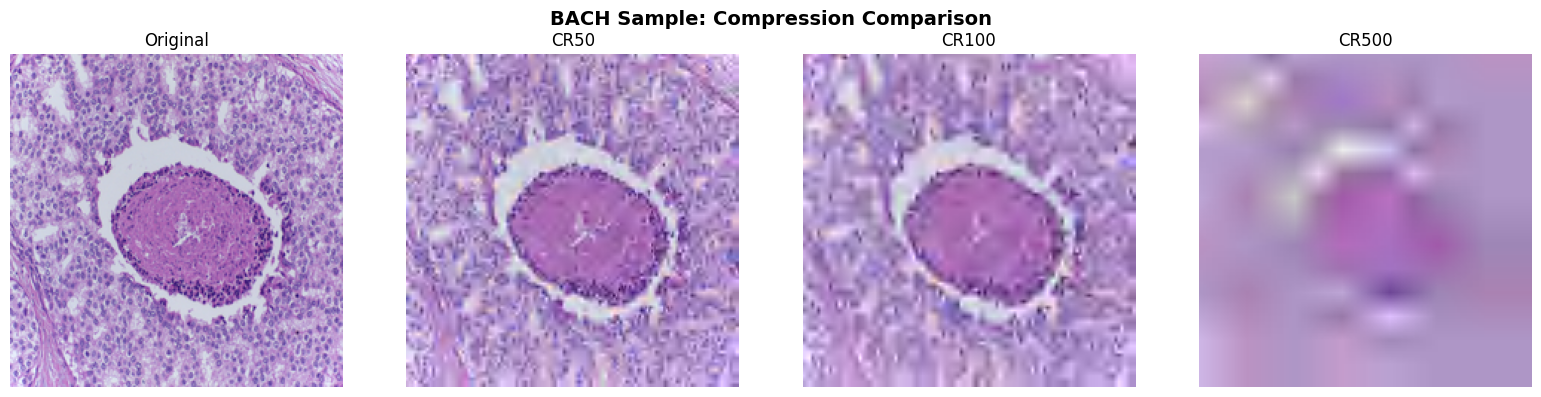


🎉 BACH DATASET READY!

📁 Location: /content/drive/MyDrive/BACH_PLOS_ONE/BACH_Split

📋 Structure:
   /content/drive/MyDrive/BACH_PLOS_ONE/BACH_Split/
   ├── CR1_original/
   │   ├── train/benign/
   │   ├── train/malignant/
   │   ├── val/...
   │   └── test/...
   ├── CR15/
   ├── CR25/
   └── ... (same structure)


In [9]:
print("="*60)
print("🔍 FINAL DATASET VERIFICATION")
print("="*60)

print("\n📊 Image counts per compression level:")
print("-" * 70)
print(f"{'CR Level':<15} {'Train':<10} {'Val':<10} {'Test':<10} {'Total':<10}")
print("-" * 70)

for cr in ['CR1_original'] + [f'CR{c}' for c in CONFIG.CR_LEVELS[1:]]:
    cr_dir = f"{CONFIG.SPLIT_DIR}/{cr}"

    counts = {'train': 0, 'val': 0, 'test': 0}
    for split in counts.keys():
        for binary_class in ['benign', 'malignant']:
            class_dir = f"{cr_dir}/{split}/{binary_class}"
            if os.path.exists(class_dir):
                counts[split] += len([f for f in os.listdir(class_dir) if f.endswith('.png')])

    total = sum(counts.values())
    status = "✅" if total > 0 else "❌"
    print(f"{status} {cr:<13} {counts['train']:<10} {counts['val']:<10} {counts['test']:<10} {total:<10}")

print("-" * 70)

# Show sample comparison
print("\n🖼️ Sample Image Comparison:")
sample_file = None
for f in os.listdir(f"{CONFIG.SPLIT_DIR}/CR1_original/test/malignant"):
    if f.endswith('.png'):
        sample_file = f
        break

if sample_file:
    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    cr_show = ['CR1_original', 'CR50', 'CR100', 'CR500']

    for i, cr in enumerate(cr_show):
        img_path = f"{CONFIG.SPLIT_DIR}/{cr}/test/malignant/{sample_file}"
        if os.path.exists(img_path):
            img = Image.open(img_path)
            axes[i].imshow(img)
            axes[i].set_title(cr.replace('CR1_original', 'Original'))
            axes[i].axis('off')

    plt.suptitle('BACH Sample: Compression Comparison', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG.BASE_DIR}/bach_compression_sample.png", dpi=150)
    plt.show()

print("\n" + "="*60)
print("🎉 BACH DATASET READY!")
print("="*60)
print(f"\n📁 Location: {CONFIG.SPLIT_DIR}")
print(f"\n📋 Structure:")
print(f"   {CONFIG.SPLIT_DIR}/")
print(f"   ├── CR1_original/")
print(f"   │   ├── train/benign/")
print(f"   │   ├── train/malignant/")
print(f"   │   ├── val/...")
print(f"   │   └── test/...")
print(f"   ├── CR15/")
print(f"   ├── CR25/")
print(f"   └── ... (same structure)")

In [10]:
# CELL 4 FIXED: Validation for ORIGINAL BreakHis folder structure
# Structure: class/SOB/subtype/patient_id/magnification/images.png

import numpy as np
import cv2
import glymur
import tempfile
import os
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

DATA_ROOT = '/content/drive/MyDrive/BACH_PLOS_ONE/BACH_Split/CR1_original'

COMPRESSION_RATIOS = [15, 25, 50, 100, 500, 1000, 5000, 10000, 11000]

# Find a sample image with original BreakHis structure:
# class/SOB/subtype/patient_id/magnification/image.png
sample_img = None

for class_name in ['benign', 'malignant']:
    sob_dir = os.path.join(DATA_ROOT, class_name, 'SOB')
    if not os.path.exists(sob_dir):
        continue

    # Get subtypes (adenosis, ductal_carcinoma, etc.)
    subtypes = [d for d in os.listdir(sob_dir) if os.path.isdir(os.path.join(sob_dir, d))]

    for subtype in subtypes:
        subtype_dir = os.path.join(sob_dir, subtype)

        # Get patient folders (SOB_B_A_14-22549AB, etc.)
        patients = [d for d in os.listdir(subtype_dir) if os.path.isdir(os.path.join(subtype_dir, d))]

        for patient in patients:
            patient_dir = os.path.join(subtype_dir, patient)

            # Get magnification folders (40X, 100X, 200X, 400X)
            mags = [d for d in os.listdir(patient_dir) if os.path.isdir(os.path.join(patient_dir, d))]

            for mag in mags:
                mag_dir = os.path.join(patient_dir, mag)

                # Get image files
                files = [f for f in os.listdir(mag_dir) if f.lower().endswith('.png')]

                if files:
                    sample_img = os.path.join(mag_dir, files[0])
                    print(f"✅ Found image!")
                    print(f"   Path: {class_name}/SOB/{subtype}/{patient}/{mag}/")
                    print(f"   File: {files[0]}")
                    break
            if sample_img:
                break
        if sample_img:
            break
    if sample_img:
        break

if sample_img is None:
    print("❌ No images found!")
    print("\nLet's search recursively...")

    # Fallback: recursive search
    for root, dirs, files in os.walk(DATA_ROOT):
        image_files = [f for f in files if f.lower().endswith('.png')]
        if image_files:
            sample_img = os.path.join(root, image_files[0])
            print(f"✅ Found image at: {root}")
            print(f"   File: {image_files[0]}")
            break

if sample_img is None:
    print("❌ No PNG images found anywhere!")
else:
    print(f"\n{'='*80}")
    print(f"COMPRESSION VALIDATION TEST")
    print(f"{'='*80}\n")

    # Load image
    img = cv2.imread(sample_img)
    if img is None:
        print(f"❌ Could not load image: {sample_img}")
    else:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w, c = img_rgb.shape
        original_bytes = h * w * c

        print(f"Image size: {w}x{h}x{c} = {original_bytes:,} bytes ({original_bytes/1024:.1f} KB)")
        print(f"This should be ~700x460 for original BreakHis\n")

        print(f"{'CR':<10} {'Achieved':<12} {'Size(bytes)':<12} {'BPP':<10} {'PSNR(dB)':<12} {'SSIM':<10} {'Status'}")
        print("-"*80)

        for cr in COMPRESSION_RATIOS:
            temp_path = tempfile.mktemp(suffix='.jp2')
            try:
                glymur.Jp2k(temp_path, data=img_rgb, cratios=[cr])
                compressed_size = os.path.getsize(temp_path)

                jp2 = glymur.Jp2k(temp_path)
                decompressed = jp2[:]
                if decompressed.dtype != np.uint8:
                    decompressed = np.clip(decompressed, 0, 255).astype(np.uint8)

                achieved_cr = original_bytes / compressed_size
                bpp = (compressed_size * 8) / (h * w)
                psnr_val = psnr(img_rgb, decompressed, data_range=255)
                ssim_val = ssim(img_rgb, decompressed, channel_axis=2, data_range=255)

                if psnr_val < 20:
                    status = "⚠️ UNUSABLE"
                elif psnr_val < 25:
                    status = "⚠️ VERY POOR"
                elif psnr_val < 30:
                    status = "⚠️ POOR"
                elif psnr_val < 40:
                    status = "OK"
                else:
                    status = "✓ GOOD"

                cr_name = f"CR{cr}" if cr < 1000 else f"CR{cr//1000}K"
                print(f"{cr_name:<10} {achieved_cr:<12.1f} {compressed_size:<12} {bpp:<10.4f} {psnr_val:<12.2f} {ssim_val:<10.4f} {status}")

            except Exception as e:
                print(f"CR{cr}: FAILED - {e}")
            finally:
                if os.path.exists(temp_path):
                    os.remove(temp_path)

        print("\n" + "="*80)
        print("REFERENCE: Jo et al. (2021) PSNR for 16-bit mammograms:")
        print("CR15:99dB | CR100:75dB | CR1K:64dB | CR5K:57dB | CR10K:56dB")
        print("="*80)

        # Check if image size is correct
        if w >= 700 and h >= 460:
            print("\n✅ Image size looks correct for original BreakHis!")
        else:
            print(f"\n⚠️ Image size ({w}x{h}) is smaller than expected (700x460)")
            print("   Make sure you're using the original unresized images")

❌ No images found!

Let's search recursively...
✅ Found image at: /content/drive/MyDrive/BACH_PLOS_ONE/BACH_Split/CR1_original/train/benign
   File: n029.png

COMPRESSION VALIDATION TEST

Image size: 224x224x3 = 150,528 bytes (147.0 KB)
This should be ~700x460 for original BreakHis

CR         Achieved     Size(bytes)  BPP        PSNR(dB)     SSIM       Status
--------------------------------------------------------------------------------
CR15       15.0         10043        1.6012     27.18        0.8581     ⚠️ POOR
CR25       24.9         6034         0.9621     24.97        0.8007     ⚠️ VERY POOR
CR50       50.1         3003         0.4788     22.95        0.7105     ⚠️ VERY POOR
CR100      99.4         1514         0.2414     21.28        0.5825     ⚠️ VERY POOR
CR500      480.9        313          0.0499     18.23        0.2825     ⚠️ UNUSABLE
CR1K       590.3        255          0.0407     14.35        0.2559     ⚠️ UNUSABLE
CR5K       590.3        255          0.0407     14.35

In [12]:
# ============================================================
# COMPREHENSIVE IMAGE FEATURE ANALYSIS
# For BreakHis Histopathology Dataset
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import cv2
from skimage import feature, filters, measure, color
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from scipy import fft, ndimage
from scipy.stats import entropy, skew, kurtosis
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')


# Configuration
DATA_DIR = '/content/drive/MyDrive/BACH_PLOS_ONE/BACH_Split'
OUTPUT_DIR = '/content/drive/MyDrive/BACH_PLOS_ONE/BACH_analysis'
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, 'figures'), exist_ok=True)

CR_LEVELS = ['CR1_original', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1000']
CR_LABELS = ['Original', 'CR15', 'CR25', 'CR50', 'CR100', 'CR500', 'CR1K']

print("="*70)
print("COMPREHENSIVE IMAGE FEATURE ANALYSIS")
print("="*70)


# ============================================================
# 1. BASIC IMAGE STATISTICS
# ============================================================

def analyze_basic_statistics(data_dir, n_samples=500):
    """Analyze basic image statistics across compression levels."""

    print("\n" + "="*50)
    print("1. BASIC IMAGE STATISTICS")
    print("="*50)

    results = []

    for cr in CR_LEVELS:
        print(f"\n  Analyzing {cr}...")

        cr_stats = {
            'cr_level': cr,
            'heights': [],
            'widths': [],
            'mean_r': [], 'mean_g': [], 'mean_b': [],
            'std_r': [], 'std_g': [], 'std_b': [],
            'brightness': [],
            'contrast': [],
            'entropy': []
        }

        # Sample images
        count = 0
        for split in ['train', 'val', 'test']:
            for class_name in ['benign', 'malignant']:
                class_dir = os.path.join(data_dir, cr, split, class_name)

                if not os.path.exists(class_dir):
                    continue

                for mag in os.listdir(class_dir):
                    mag_dir = os.path.join(class_dir, mag)

                    if not os.path.isdir(mag_dir):
                        continue

                    for filename in os.listdir(mag_dir):
                        if count >= n_samples:
                            break

                        if filename.endswith('.png'):
                            img_path = os.path.join(mag_dir, filename)
                            img = cv2.imread(img_path)
                            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

                            # Basic stats
                            h, w, c = img_rgb.shape
                            cr_stats['heights'].append(h)
                            cr_stats['widths'].append(w)

                            # Color channel stats
                            cr_stats['mean_r'].append(np.mean(img_rgb[:,:,0]))
                            cr_stats['mean_g'].append(np.mean(img_rgb[:,:,1]))
                            cr_stats['mean_b'].append(np.mean(img_rgb[:,:,2]))
                            cr_stats['std_r'].append(np.std(img_rgb[:,:,0]))
                            cr_stats['std_g'].append(np.std(img_rgb[:,:,1]))
                            cr_stats['std_b'].append(np.std(img_rgb[:,:,2]))

                            # Brightness (mean of grayscale)
                            gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                            cr_stats['brightness'].append(np.mean(gray))

                            # Contrast (std of grayscale)
                            cr_stats['contrast'].append(np.std(gray))

                            # Entropy
                            hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
                            hist = hist / hist.sum()
                            cr_stats['entropy'].append(entropy(hist.flatten() + 1e-10))

                            count += 1

                    if count >= n_samples:
                        break
                if count >= n_samples:
                    break
            if count >= n_samples:
                break

        # Aggregate stats
        results.append({
            'cr_level': cr,
            'n_samples': count,
            'height_mean': np.mean(cr_stats['heights']),
            'width_mean': np.mean(cr_stats['widths']),
            'mean_r': np.mean(cr_stats['mean_r']),
            'mean_g': np.mean(cr_stats['mean_g']),
            'mean_b': np.mean(cr_stats['mean_b']),
            'std_r': np.mean(cr_stats['std_r']),
            'std_g': np.mean(cr_stats['std_g']),
            'std_b': np.mean(cr_stats['std_b']),
            'brightness_mean': np.mean(cr_stats['brightness']),
            'brightness_std': np.std(cr_stats['brightness']),
            'contrast_mean': np.mean(cr_stats['contrast']),
            'contrast_std': np.std(cr_stats['contrast']),
            'entropy_mean': np.mean(cr_stats['entropy']),
            'entropy_std': np.std(cr_stats['entropy'])
        })

        print(f"    Brightness: {results[-1]['brightness_mean']:.2f} ± {results[-1]['brightness_std']:.2f}")
        print(f"    Contrast: {results[-1]['contrast_mean']:.2f} ± {results[-1]['contrast_std']:.2f}")
        print(f"    Entropy: {results[-1]['entropy_mean']:.4f} ± {results[-1]['entropy_std']:.4f}")

    stats_df = pd.DataFrame(results)
    stats_df.to_csv(os.path.join(OUTPUT_DIR, 'basic_statistics.csv'), index=False)

    return stats_df


# ============================================================
# 2. TEXTURE ANALYSIS (GLCM & LBP)
# ============================================================

def extract_glcm_features(gray_image, distances=[1, 3, 5], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4]):
    """Extract GLCM texture features."""

    # Normalize to 0-255 and convert to uint8
    gray = (gray_image * 255).astype(np.uint8) if gray_image.max() <= 1 else gray_image.astype(np.uint8)

    # Compute GLCM
    glcm = graycomatrix(gray, distances=distances, angles=angles, levels=256, symmetric=True, normed=True)

    # Extract properties
    features = {
        'contrast': graycoprops(glcm, 'contrast').mean(),
        'dissimilarity': graycoprops(glcm, 'dissimilarity').mean(),
        'homogeneity': graycoprops(glcm, 'homogeneity').mean(),
        'energy': graycoprops(glcm, 'energy').mean(),
        'correlation': graycoprops(glcm, 'correlation').mean(),
        'ASM': graycoprops(glcm, 'ASM').mean()
    }

    return features


def extract_lbp_features(gray_image, radius=3, n_points=24):
    """Extract LBP texture features."""

    gray = (gray_image * 255).astype(np.uint8) if gray_image.max() <= 1 else gray_image.astype(np.uint8)

    lbp = local_binary_pattern(gray, n_points, radius, method='uniform')

    # Histogram of LBP
    n_bins = n_points + 2
    hist, _ = np.histogram(lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True)

    return {
        'lbp_mean': np.mean(lbp),
        'lbp_std': np.std(lbp),
        'lbp_entropy': entropy(hist + 1e-10),
        'lbp_uniformity': np.sum(hist ** 2)
    }


def analyze_texture_features(data_dir, n_samples=200):
    """Analyze texture features across compression levels and classes."""

    print("\n" + "="*50)
    print("2. TEXTURE ANALYSIS (GLCM & LBP)")
    print("="*50)

    results = []

    for cr in CR_LEVELS:
        print(f"\n  Analyzing {cr}...")

        for class_name in ['benign', 'malignant']:
            class_features = []
            count = 0

            for split in ['train', 'val', 'test']:
                class_dir = os.path.join(data_dir, cr, split, class_name)

                if not os.path.exists(class_dir):
                    continue

                for mag in os.listdir(class_dir):
                    mag_dir = os.path.join(class_dir, mag)

                    if not os.path.isdir(mag_dir):
                        continue

                    for filename in os.listdir(mag_dir):
                        if count >= n_samples // 2:
                            break

                        if filename.endswith('.png'):
                            img_path = os.path.join(mag_dir, filename)
                            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

                            # Resize for consistent analysis
                            img = cv2.resize(img, (224, 224))

                            # Extract features
                            glcm_feat = extract_glcm_features(img)
                            lbp_feat = extract_lbp_features(img)

                            features = {**glcm_feat, **lbp_feat}
                            features['class'] = class_name
                            features['cr_level'] = cr

                            class_features.append(features)
                            count += 1

                    if count >= n_samples // 2:
                        break
                if count >= n_samples // 2:
                    break

            results.extend(class_features)
            print(f"    {class_name}: {len(class_features)} samples")

    texture_df = pd.DataFrame(results)
    texture_df.to_csv(os.path.join(OUTPUT_DIR, 'texture_features.csv'), index=False)

    return texture_df


# ============================================================
# 3. FREQUENCY DOMAIN ANALYSIS
# ============================================================

def analyze_frequency_features(data_dir, n_samples=100):
    """Analyze frequency domain features - critical for compression analysis."""

    print("\n" + "="*50)
    print("3. FREQUENCY DOMAIN ANALYSIS")
    print("="*50)

    results = []

    for cr in CR_LEVELS:
        print(f"\n  Analyzing {cr}...")

        freq_stats = {
            'low_freq_energy': [],
            'mid_freq_energy': [],
            'high_freq_energy': [],
            'spectral_centroid': [],
            'spectral_spread': []
        }

        count = 0
        for split in ['train', 'val', 'test']:
            for class_name in ['benign', 'malignant']:
                class_dir = os.path.join(data_dir, cr, split, class_name)

                if not os.path.exists(class_dir):
                    continue

                for mag in os.listdir(class_dir):
                    mag_dir = os.path.join(class_dir, mag)

                    if not os.path.isdir(mag_dir):
                        continue

                    for filename in os.listdir(mag_dir):
                        if count >= n_samples:
                            break

                        if filename.endswith('.png'):
                            img_path = os.path.join(mag_dir, filename)
                            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
                            img = cv2.resize(img, (224, 224))

                            # FFT
                            f_transform = np.fft.fft2(img)
                            f_shift = np.fft.fftshift(f_transform)
                            magnitude = np.abs(f_shift)

                            # Create frequency bands
                            rows, cols = img.shape
                            crow, ccol = rows // 2, cols // 2

                            # Distance from center
                            y, x = np.ogrid[:rows, :cols]
                            dist = np.sqrt((x - ccol)**2 + (y - crow)**2)

                            # Frequency bands (low, mid, high)
                            max_dist = np.sqrt(crow**2 + ccol**2)
                            low_mask = dist < max_dist * 0.1
                            mid_mask = (dist >= max_dist * 0.1) & (dist < max_dist * 0.5)
                            high_mask = dist >= max_dist * 0.5

                            total_energy = np.sum(magnitude ** 2)

                            freq_stats['low_freq_energy'].append(np.sum(magnitude[low_mask] ** 2) / total_energy)
                            freq_stats['mid_freq_energy'].append(np.sum(magnitude[mid_mask] ** 2) / total_energy)
                            freq_stats['high_freq_energy'].append(np.sum(magnitude[high_mask] ** 2) / total_energy)

                            # Spectral centroid
                            freq_stats['spectral_centroid'].append(np.sum(dist * magnitude) / np.sum(magnitude))

                            # Spectral spread
                            centroid = freq_stats['spectral_centroid'][-1]
                            freq_stats['spectral_spread'].append(
                                np.sqrt(np.sum(((dist - centroid) ** 2) * magnitude) / np.sum(magnitude))
                            )

                            count += 1

                    if count >= n_samples:
                        break
                if count >= n_samples:
                    break
            if count >= n_samples:
                break

        results.append({
            'cr_level': cr,
            'low_freq_energy': np.mean(freq_stats['low_freq_energy']),
            'mid_freq_energy': np.mean(freq_stats['mid_freq_energy']),
            'high_freq_energy': np.mean(freq_stats['high_freq_energy']),
            'high_freq_std': np.std(freq_stats['high_freq_energy']),
            'spectral_centroid': np.mean(freq_stats['spectral_centroid']),
            'spectral_spread': np.mean(freq_stats['spectral_spread'])
        })

        print(f"    Low freq: {results[-1]['low_freq_energy']:.4f}")
        print(f"    Mid freq: {results[-1]['mid_freq_energy']:.4f}")
        print(f"    High freq: {results[-1]['high_freq_energy']:.4f}")

    freq_df = pd.DataFrame(results)
    freq_df.to_csv(os.path.join(OUTPUT_DIR, 'frequency_features.csv'), index=False)

    return freq_df


# ============================================================
# 4. CLASS DISCRIMINATIVE FEATURES
# ============================================================

def analyze_class_features(data_dir, n_samples=300):
    """Analyze features that distinguish benign vs malignant."""

    print("\n" + "="*50)
    print("4. CLASS DISCRIMINATIVE FEATURE ANALYSIS")
    print("="*50)

    results = []

    cr = 'CR1_original'  # Analyze original images

    for class_name in ['benign', 'malignant']:
        print(f"\n  Analyzing {class_name}...")

        count = 0
        for split in ['train', 'val', 'test']:
            class_dir = os.path.join(data_dir, cr, split, class_name)

            if not os.path.exists(class_dir):
                continue

            for mag in os.listdir(class_dir):
                mag_dir = os.path.join(class_dir, mag)

                if not os.path.isdir(mag_dir):
                    continue

                for filename in os.listdir(mag_dir):
                    if count >= n_samples:
                        break

                    if filename.endswith('.png'):
                        img_path = os.path.join(mag_dir, filename)
                        img = cv2.imread(img_path)
                        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                        gray = cv2.resize(gray, (224, 224))

                        # Color features
                        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

                        # Morphological features
                        edges = cv2.Canny(gray, 50, 150)

                        # Extract features
                        features = {
                            'class': class_name,
                            'magnification': mag,

                            # Color features
                            'hue_mean': np.mean(hsv[:,:,0]),
                            'hue_std': np.std(hsv[:,:,0]),
                            'saturation_mean': np.mean(hsv[:,:,1]),
                            'saturation_std': np.std(hsv[:,:,1]),
                            'value_mean': np.mean(hsv[:,:,2]),
                            'value_std': np.std(hsv[:,:,2]),

                            # Intensity features
                            'intensity_mean': np.mean(gray),
                            'intensity_std': np.std(gray),
                            'intensity_skew': skew(gray.flatten()),
                            'intensity_kurtosis': kurtosis(gray.flatten()),

                            # Edge features
                            'edge_density': np.sum(edges > 0) / edges.size,
                            'edge_mean': np.mean(edges),

                            # Texture features (GLCM)
                            **extract_glcm_features(gray),

                            # LBP features
                            **extract_lbp_features(gray)
                        }

                        results.append(features)
                        count += 1

                if count >= n_samples:
                    break
            if count >= n_samples:
                break

    class_df = pd.DataFrame(results)
    class_df.to_csv(os.path.join(OUTPUT_DIR, 'class_discriminative_features.csv'), index=False)

    # Analyze which features best separate classes
    print("\n  Feature Importance (Benign vs Malignant):")
    print("  " + "-"*40)

    numeric_cols = class_df.select_dtypes(include=[np.number]).columns

    feature_importance = []
    for col in numeric_cols:
        benign_vals = class_df[class_df['class'] == 'benign'][col]
        malignant_vals = class_df[class_df['class'] == 'malignant'][col]

        # t-test
        from scipy.stats import ttest_ind
        t_stat, p_value = ttest_ind(benign_vals, malignant_vals)

        # Effect size (Cohen's d)
        pooled_std = np.sqrt((benign_vals.std()**2 + malignant_vals.std()**2) / 2)
        cohens_d = abs(benign_vals.mean() - malignant_vals.mean()) / pooled_std if pooled_std > 0 else 0

        feature_importance.append({
            'feature': col,
            'benign_mean': benign_vals.mean(),
            'malignant_mean': malignant_vals.mean(),
            'p_value': p_value,
            'cohens_d': cohens_d,
            'significant': p_value < 0.05
        })

    importance_df = pd.DataFrame(feature_importance)
    importance_df = importance_df.sort_values('cohens_d', ascending=False)
    importance_df.to_csv(os.path.join(OUTPUT_DIR, 'feature_importance.csv'), index=False)

    # Print top 10 discriminative features
    print("\n  Top 10 Discriminative Features:")
    for _, row in importance_df.head(10).iterrows():
        sig = "***" if row['p_value'] < 0.001 else "**" if row['p_value'] < 0.01 else "*" if row['p_value'] < 0.05 else ""
        print(f"    {row['feature']}: Cohen's d = {row['cohens_d']:.3f} {sig}")

    return class_df, importance_df


# ============================================================
# 5. COMPRESSION IMPACT ON FEATURES
# ============================================================

def analyze_compression_impact(data_dir, n_samples=100):
    """Analyze how compression affects discriminative features."""

    print("\n" + "="*50)
    print("5. COMPRESSION IMPACT ON FEATURES")
    print("="*50)

    # Track same images across compression levels
    results = []

    # Get sample filenames from original
    sample_files = []
    cr = 'CR1_original'

    for split in ['test']:
        for class_name in ['benign', 'malignant']:
            class_dir = os.path.join(data_dir, cr, split, class_name)

            if not os.path.exists(class_dir):
                continue

            for mag in os.listdir(class_dir):
                mag_dir = os.path.join(class_dir, mag)

                if not os.path.isdir(mag_dir):
                    continue

                for filename in os.listdir(mag_dir)[:n_samples // 4]:
                    if filename.endswith('.png'):
                        sample_files.append({
                            'filename': filename,
                            'subpath': os.path.join(split, class_name, mag),
                            'class': class_name,
                            'mag': mag
                        })

    print(f"  Tracking {len(sample_files)} images across compression levels...")

    for sample in sample_files:
        for cr in CR_LEVELS:
            img_path = os.path.join(data_dir, cr, sample['subpath'], sample['filename'])

            if not os.path.exists(img_path):
                continue

            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
            img = cv2.resize(img, (224, 224))

            # Extract key features
            glcm = extract_glcm_features(img)
            lbp = extract_lbp_features(img)

            # Frequency analysis
            f_transform = np.fft.fft2(img)
            f_shift = np.fft.fftshift(f_transform)
            magnitude = np.abs(f_shift)

            rows, cols = img.shape
            crow, ccol = rows // 2, cols // 2
            y, x = np.ogrid[:rows, :cols]
            dist = np.sqrt((x - ccol)**2 + (y - crow)**2)
            max_dist = np.sqrt(crow**2 + ccol**2)

            high_mask = dist >= max_dist * 0.5
            total_energy = np.sum(magnitude ** 2)
            high_freq_ratio = np.sum(magnitude[high_mask] ** 2) / total_energy

            results.append({
                'filename': sample['filename'],
                'class': sample['class'],
                'magnification': sample['mag'],
                'cr_level': cr,
                'contrast': glcm['contrast'],
                'homogeneity': glcm['homogeneity'],
                'energy': glcm['energy'],
                'correlation': glcm['correlation'],
                'lbp_entropy': lbp['lbp_entropy'],
                'high_freq_ratio': high_freq_ratio,
                'intensity_std': np.std(img),
                'edge_density': np.sum(cv2.Canny(img, 50, 150) > 0) / img.size
            })

    impact_df = pd.DataFrame(results)
    impact_df.to_csv(os.path.join(OUTPUT_DIR, 'compression_impact.csv'), index=False)

    # Calculate relative change from original
    print("\n  Feature Degradation from Original:")
    print("  " + "-"*50)

    features_to_track = ['contrast', 'homogeneity', 'energy', 'correlation',
                         'lbp_entropy', 'high_freq_ratio', 'edge_density']

    degradation_results = []

    for cr in CR_LEVELS[1:]:  # Skip original
        cr_data = impact_df[impact_df['cr_level'] == cr]
        orig_data = impact_df[impact_df['cr_level'] == 'CR1_original']

        row = {'cr_level': cr}

        for feat in features_to_track:
            # Match by filename
            merged = cr_data.merge(orig_data[['filename', feat]], on='filename', suffixes=('_cr', '_orig'))

            if len(merged) > 0:
                relative_change = ((merged[f'{feat}_cr'] - merged[f'{feat}_orig']) /
                                   (merged[f'{feat}_orig'] + 1e-10)).mean() * 100
                row[f'{feat}_change_pct'] = relative_change

        degradation_results.append(row)
        print(f"    {cr}:")
        print(f"      High-freq loss: {row.get('high_freq_ratio_change_pct', 0):.1f}%")
        print(f"      Edge density change: {row.get('edge_density_change_pct', 0):.1f}%")
        print(f"      Texture (contrast) change: {row.get('contrast_change_pct', 0):.1f}%")

    degradation_df = pd.DataFrame(degradation_results)
    degradation_df.to_csv(os.path.join(OUTPUT_DIR, 'feature_degradation.csv'), index=False)

    return impact_df, degradation_df


# ============================================================
# 6. VISUALIZATIONS
# ============================================================

def create_visualizations(output_dir):
    """Create comprehensive visualizations."""

    print("\n" + "="*50)
    print("6. CREATING VISUALIZATIONS")
    print("="*50)

    # Load analysis results
    basic_stats = pd.read_csv(os.path.join(output_dir, 'basic_statistics.csv'))
    texture_df = pd.read_csv(os.path.join(output_dir, 'texture_features.csv'))
    freq_df = pd.read_csv(os.path.join(output_dir, 'frequency_features.csv'))
    class_df = pd.read_csv(os.path.join(output_dir, 'class_discriminative_features.csv'))
    importance_df = pd.read_csv(os.path.join(output_dir, 'feature_importance.csv'))

    # ========== FIGURE 1: Basic Statistics vs Compression ==========
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    # Entropy
    ax = axes[0, 0]
    ax.bar(CR_LABELS, basic_stats['entropy_mean'], yerr=basic_stats['entropy_std'],
           capsize=5, color='steelblue', edgecolor='black')
    ax.set_ylabel('Entropy', fontsize=12)
    ax.set_title('Image Entropy vs Compression', fontsize=13, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)

    # Contrast
    ax = axes[0, 1]
    ax.bar(CR_LABELS, basic_stats['contrast_mean'], yerr=basic_stats['contrast_std'],
           capsize=5, color='coral', edgecolor='black')
    ax.set_ylabel('Contrast (Std)', fontsize=12)
    ax.set_title('Image Contrast vs Compression', fontsize=13, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)

    # Brightness
    ax = axes[1, 0]
    ax.bar(CR_LABELS, basic_stats['brightness_mean'], yerr=basic_stats['brightness_std'],
           capsize=5, color='mediumseagreen', edgecolor='black')
    ax.set_ylabel('Brightness', fontsize=12)
    ax.set_title('Image Brightness vs Compression', fontsize=13, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)

    # Color channel means
    ax = axes[1, 1]
    x = np.arange(len(CR_LABELS))
    width = 0.25
    ax.bar(x - width, basic_stats['mean_r'], width, label='Red', color='red', alpha=0.7)
    ax.bar(x, basic_stats['mean_g'], width, label='Green', color='green', alpha=0.7)
    ax.bar(x + width, basic_stats['mean_b'], width, label='Blue', color='blue', alpha=0.7)
    ax.set_xticks(x)
    ax.set_xticklabels(CR_LABELS, rotation=45)
    ax.set_ylabel('Mean Intensity', fontsize=12)
    ax.set_title('Color Channel Means vs Compression', fontsize=13, fontweight='bold')
    ax.legend()

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'figures', 'basic_statistics.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # ========== FIGURE 2: Frequency Domain Analysis ==========
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Frequency band distribution
    ax = axes[0]
    x = np.arange(len(CR_LABELS))
    width = 0.25
    ax.bar(x - width, freq_df['low_freq_energy'], width, label='Low Freq', color='blue')
    ax.bar(x, freq_df['mid_freq_energy'], width, label='Mid Freq', color='green')
    ax.bar(x + width, freq_df['high_freq_energy'], width, label='High Freq', color='red')
    ax.set_xticks(x)
    ax.set_xticklabels(CR_LABELS, rotation=45)
    ax.set_ylabel('Energy Ratio', fontsize=12)
    ax.set_title('Frequency Band Energy Distribution', fontsize=13, fontweight='bold')
    ax.legend()

    # High frequency loss
    ax = axes[1]
    original_high_freq = freq_df[freq_df['cr_level'] == 'CR1_original']['high_freq_energy'].values[0]
    high_freq_loss = (original_high_freq - freq_df['high_freq_energy']) / original_high_freq * 100
    ax.plot(CR_LABELS, high_freq_loss, 'o-', linewidth=2, markersize=10, color='red')
    ax.set_ylabel('High Frequency Loss (%)', fontsize=12)
    ax.set_title('High Frequency Content Loss vs Compression', fontsize=13, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
    ax.axhline(y=50, color='orange', linestyle='--', label='50% loss threshold')
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'figures', 'frequency_analysis.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # ========== FIGURE 3: Class Discriminative Features ==========
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    top_features = importance_df.head(6)['feature'].tolist()

    for idx, feat in enumerate(top_features):
        ax = axes[idx // 3, idx % 3]

        benign_vals = class_df[class_df['class'] == 'benign'][feat]
        malignant_vals = class_df[class_df['class'] == 'malignant'][feat]

        ax.hist(benign_vals, bins=30, alpha=0.6, label='Benign', color='green', density=True)
        ax.hist(malignant_vals, bins=30, alpha=0.6, label='Malignant', color='red', density=True)
        ax.set_xlabel(feat, fontsize=11)
        ax.set_ylabel('Density', fontsize=11)
        ax.set_title(f'{feat}\n(Cohen\'s d = {importance_df[importance_df["feature"]==feat]["cohens_d"].values[0]:.3f})',
                    fontsize=12, fontweight='bold')
        ax.legend()

    plt.suptitle('Top Discriminative Features: Benign vs Malignant', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'figures', 'class_discriminative_features.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # ========== FIGURE 4: Texture Feature Comparison ==========
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))

    texture_features = ['contrast', 'homogeneity', 'energy', 'correlation']

    for idx, feat in enumerate(texture_features):
        ax = axes[idx // 2, idx % 2]

        # Group by CR and class
        grouped = texture_df.groupby(['cr_level', 'class'])[feat].mean().unstack()
        grouped = grouped.reindex(CR_LEVELS)

        x = np.arange(len(CR_LEVELS))
        width = 0.35

        ax.bar(x - width/2, grouped['benign'], width, label='Benign', color='green', alpha=0.7)
        ax.bar(x + width/2, grouped['malignant'], width, label='Malignant', color='red', alpha=0.7)
        ax.set_xticks(x)
        ax.set_xticklabels(CR_LABELS, rotation=45)
        ax.set_ylabel(feat.title(), fontsize=12)
        ax.set_title(f'GLCM {feat.title()} vs Compression', fontsize=13, fontweight='bold')
        ax.legend()

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, 'figures', 'texture_analysis.png'), dpi=300, bbox_inches='tight')
    plt.show()

    print("\n✅ All visualizations saved!")


# ============================================================
# 7. MODEL RECOMMENDATION BASED ON ANALYSIS
# ============================================================

def generate_model_recommendations(output_dir):
    """Generate model recommendations based on feature analysis."""

    print("\n" + "="*50)
    print("7. MODEL RECOMMENDATIONS")
    print("="*50)

    # Load analysis results
    importance_df = pd.read_csv(os.path.join(output_dir, 'feature_importance.csv'))
    freq_df = pd.read_csv(os.path.join(output_dir, 'frequency_features.csv'))

    print("\n📊 KEY FINDINGS:")
    print("-" * 50)

    # Top discriminative features
    top_features = importance_df[importance_df['cohens_d'] > 0.3]['feature'].tolist()
    print(f"\n1. Top Discriminative Features (Cohen's d > 0.3):")
    for feat in top_features[:5]:
        d = importance_df[importance_df['feature'] == feat]['cohens_d'].values[0]
        print(f"   - {feat}: d = {d:.3f}")

    # Compression impact
    print(f"\n2. Compression Impact on High Frequency:")
    original_hf = freq_df[freq_df['cr_level'] == 'CR1_original']['high_freq_energy'].values[0]
    for _, row in freq_df.iterrows():
        loss = (original_hf - row['high_freq_energy']) / original_hf * 100
        print(f"   - {row['cr_level']}: {loss:.1f}% loss")

    # Model recommendations
    print("\n" + "="*50)
    print("🎯 MODEL RECOMMENDATIONS")
    print("="*50)

    recommendations = """
    Based on the feature analysis:

    1. TEXTURE FEATURES ARE HIGHLY DISCRIMINATIVE
       → Use models with strong texture extraction:
       - DenseNet121 (dense connections preserve fine details)
       - Xception (depthwise separable convolutions for textures)

    2. HIGH FREQUENCY CONTENT IS CRITICAL BUT LOST AT HIGH CR
       → Use models that can learn from lower frequencies:
       - Multi-scale architectures (Inception, DenseNet)
       - Avoid relying solely on fine edge details

    3. COLOR FEATURES PROVIDE MODERATE DISCRIMINATION
       → Ensure models use all 3 color channels
       → Consider color augmentation during training

    4. RECOMMENDED ARCHITECTURE COMBINATIONS:

       A) Xception + DenseNet121 (Current choice - VALIDATED)
          - Xception: Efficient texture extraction
          - DenseNet: Multi-scale feature preservation

       B) Inception + ResNet50 (Alternative)
          - Inception: Multi-scale processing
          - ResNet: Robust feature learning

       C) EfficientNet (Single model alternative)
          - Balanced efficiency and accuracy
          - Good at multiple scales

    5. DATA AUGMENTATION RECOMMENDATIONS:
       - Color jitter (saturation important for staining)
       - Rotation/flip (tissue orientation invariant)
       - Slight blur (simulate compression artifacts)

    6. COMPRESSION-AWARE TRAINING RECOMMENDATION:
       - Train on mixed CR levels (Original + CR15 + CR25 + CR50)
       - This prepares model for high-frequency loss
    """

    print(recommendations)

    # Save recommendations
    with open(os.path.join(output_dir, 'model_recommendations.txt'), 'w') as f:
        f.write(recommendations)

    return recommendations


# ============================================================
# MAIN EXECUTION
# ============================================================

if __name__ == '__main__':

    print(f"\nStart Time: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

    # Run all analyses
    basic_stats = analyze_basic_statistics(DATA_DIR, n_samples=500)
    texture_df = analyze_texture_features(DATA_DIR, n_samples=200)
    freq_df = analyze_frequency_features(DATA_DIR, n_samples=100)
    class_df, importance_df = analyze_class_features(DATA_DIR, n_samples=300)
    impact_df, degradation_df = analyze_compression_impact(DATA_DIR, n_samples=100)

    # Create visualizations
    create_visualizations(OUTPUT_DIR)

    # Generate recommendations
    recommendations = generate_model_recommendations(OUTPUT_DIR)

    print("\n" + "="*70)
    print("✅ ANALYSIS COMPLETE!")
    print("="*70)
    print(f"\nResults saved to: {OUTPUT_DIR}")
    print(f"End Time: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

    print("\n📁 Generated Files:")
    print("   - basic_statistics.csv")
    print("   - texture_features.csv")
    print("   - frequency_features.csv")
    print("   - class_discriminative_features.csv")
    print("   - feature_importance.csv")
    print("   - compression_impact.csv")
    print("   - feature_degradation.csv")
    print("   - model_recommendations.txt")
    print("   - figures/basic_statistics.png")
    print("   - figures/frequency_analysis.png")
    print("   - figures/class_discriminative_features.png")
    print("   - figures/texture_analysis.png")

COMPREHENSIVE IMAGE FEATURE ANALYSIS

Start Time: 2026-02-27 22:46:25

1. BASIC IMAGE STATISTICS

  Analyzing CR1_original...
    Brightness: nan ± nan
    Contrast: nan ± nan
    Entropy: nan ± nan

  Analyzing CR15...
    Brightness: nan ± nan
    Contrast: nan ± nan
    Entropy: nan ± nan

  Analyzing CR25...
    Brightness: nan ± nan
    Contrast: nan ± nan
    Entropy: nan ± nan

  Analyzing CR50...
    Brightness: nan ± nan
    Contrast: nan ± nan
    Entropy: nan ± nan

  Analyzing CR100...
    Brightness: nan ± nan
    Contrast: nan ± nan
    Entropy: nan ± nan

  Analyzing CR500...
    Brightness: nan ± nan
    Contrast: nan ± nan
    Entropy: nan ± nan

  Analyzing CR1000...
    Brightness: nan ± nan
    Contrast: nan ± nan
    Entropy: nan ± nan

2. TEXTURE ANALYSIS (GLCM & LBP)

  Analyzing CR1_original...
    benign: 0 samples
    malignant: 0 samples

  Analyzing CR15...
    benign: 0 samples
    malignant: 0 samples

  Analyzing CR25...
    benign: 0 samples
    malignan

KeyError: 'cohens_d'

## 📋 Next Steps

Now that BACH is processed, you can:

1. **Run the same 3 experiments** (Adaptation, Robustness, Compression-Aware Training)
2. **Compare results** with BreakHis
3. **Generate cross-dataset analysis**

The BACH experiments notebook will be provided next!